In [1]:
#1.1 Problem Statement

#A subscription-based digital services company wants to understand customer behavior, improve revenue, and reduce customer churn.

#The company collects customer information, subscription details, usage information, and marketing data. However, it needs to analyze this data to understand which customers generate more revenue and which factors influence customer retention.

#Using Python, we will clean the dataset, perform exploratory data analysis, create meaningful features, visualize business trends, and build a Linear Regression model to predict customer revenue.

#1.2 Project Objectives
#Clean and prepare the customer subscription dataset.
#Handle missing values and duplicate records.
#Perform feature engineering.
#Analyze customer behavior and revenue trends.
#Identify relationships between subscription plans, usage, discounts, and revenue.
#Analyze customer churn.
#Build a Linear Regression model to predict customer revenue.
#Evaluate model performance and generate business recommendations.

In [3]:
print("project on pandas, matplotlip and seaborn")

project on pandas, matplotlip and seaborn


In [5]:
#Import Libraries and Load the Dataset

import pandas as pd
import numpy as np

In [7]:
df = pd.read_csv("C:\\Users\\visha\\OneDrive\\Desktop\\data anylytics course\\projects\\python\\subscription_data.csv")

In [9]:
df

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue
0,10001,56.0,Female,Chennai,12/3/2022,12/29/2022,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90
1,10002,46.0,Female,Mumbai,3/24/2021,1/25/2022,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40
2,10003,32.0,Female,Mumbai,6/15/2023,8/10/2023,Basic,783,4,0,41.93,5.0,Referral,No,3092.85
3,10004,60.0,Male,Delhi,11/13/2022,7/8/2021,Standard,545,4,1,116.41,0.0,Organic,No,2180.00
4,10005,25.0,Female,Mumbai,2/17/2022,6/25/2021,Basic,1331,30,1,81.89,10.0,Ads,No,39796.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2555,11315,61.0,Male,Bangalore,11/17/2021,10/15/2022,Basic,1194,17,1,78.57,20.0,Organic,No,20059.20
2556,10645,25.0,Female,Pune,1/15/2022,11/3/2023,Basic,1016,18,2,9.21,NaN,Email,No,18288.00
2557,12103,25.0,Female,Chennai,1/21/2022,8/14/2022,Premium,801,20,1,11.67,20.0,Organic,No,15859.80
2558,10615,NaN,Female,Pune,3/17/2022,10/7/2023,Premium,692,22,0,34.42,0.0,Ads,No,15224.00


In [11]:
#Import Libraries and Load the Dataset

df.head()

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue
0,10001,56.0,Female,Chennai,12/3/2022,12/29/2022,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90
1,10002,46.0,Female,Mumbai,3/24/2021,1/25/2022,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40
2,10003,32.0,Female,Mumbai,6/15/2023,8/10/2023,Basic,783,4,0,41.93,5.0,Referral,No,3092.85
3,10004,60.0,Male,Delhi,11/13/2022,7/8/2021,Standard,545,4,1,116.41,0.0,Organic,No,2180.00
4,10005,25.0,Female,Mumbai,2/17/2022,6/25/2021,Basic,1331,30,1,81.89,10.0,Ads,No,39796.90


In [13]:
#1.	How many rows and columns are present in the dataset?

df.shape

(2560, 15)

In [15]:
#2.	What are the data types of each column?

df.dtypes

customer_id            int64
age                  float64
gender                object
city                  object
signup_date           object
last_active_date      object
plan_type             object
monthly_fee            int64
tenure_months          int64
support_tickets        int64
avg_session_time     float64
discount_percent     float64
marketing_channel     object
churned               object
total_revenue        float64
dtype: object

In [17]:
#3.	Which columns contain missing values?

df.isna().sum()

customer_id            0
age                  105
gender                 0
city                 104
signup_date            0
last_active_date       0
plan_type              0
monthly_fee            0
tenure_months          0
support_tickets        0
avg_session_time     101
discount_percent     105
marketing_channel      0
churned                0
total_revenue          0
dtype: int64

In [19]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

age                 105
city                104
avg_session_time    101
discount_percent    105
dtype: int64

In [21]:
#4.	What percentage of missing values does each column have?

(df.isna().sum() / len(df)) * 100

customer_id          0.000000
age                  4.101562
gender               0.000000
city                 4.062500
signup_date          0.000000
last_active_date     0.000000
plan_type            0.000000
monthly_fee          0.000000
tenure_months        0.000000
support_tickets      0.000000
avg_session_time     3.945312
discount_percent     4.101562
marketing_channel    0.000000
churned              0.000000
total_revenue        0.000000
dtype: float64

In [23]:
#5.	How should missing values in the age column be handled?
# Impute using median, since age may contain outliers.

df["age"].median()

41.0

In [51]:
df["age"].fillna(df["age"].median())

0       56.0
1       46.0
2       32.0
3       60.0
4       25.0
        ... 
2555    61.0
2556    25.0
2557    25.0
2558    41.0
2559    33.0
Name: age, Length: 2560, dtype: float64

In [53]:
df["age"].isnull().sum()

0

In [55]:
#6.	How do you handle missing values in the city column?

df["city"].isnull().sum()

104

In [63]:
# fill missing city as unknow

df["city"].fillna(df["city"].mode()[0])

0         Chennai
1          Mumbai
2          Mumbai
3           Delhi
4          Mumbai
          ...    
2555    Bangalore
2556         Pune
2557      Chennai
2558         Pune
2559         Pune
Name: city, Length: 2560, dtype: object

In [65]:
df["city"].isnull().sum()

0

In [67]:
#7.	How to treat missing values in avg_session_time?

df["avg_session_time"].median()

62.59

In [69]:
df["avg_session_time"].isna().sum()

101

In [77]:
df["avg_session_time"].fillna(df["avg_session_time"].median())

0        15.75
1        37.16
2        41.93
3       116.41
4        81.89
         ...  
2555     78.57
2556      9.21
2557     11.67
2558     34.42
2559     28.31
Name: avg_session_time, Length: 2560, dtype: float64

In [79]:
df["avg_session_time"].isna().sum()

0

In [81]:
#8: How do you handle missing values in discount_percent?

df["discount_percent"].median()

10.0

In [93]:
df["discount_percent"].fillna(0)

0       15.0
1       20.0
2        5.0
3        0.0
4       10.0
        ... 
2555    20.0
2556     0.0
2557    20.0
2558     0.0
2559    20.0
Name: discount_percent, Length: 2560, dtype: float64

In [95]:
df["discount_percent"].isna().sum()

0

In [97]:
#Question 9: How do you check for duplicate records?

df.duplicated().sum()

60

In [99]:
df[df.duplicated()]

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue
2500,10060,53.0,Female,Chennai,1/29/2023,10/17/2021,Standard,476,32,2,119.63,10.0,Ads,No,15184.40
2501,10498,29.0,Male,Bangalore,11/24/2022,2/23/2022,Standard,1466,23,2,56.06,10.0,Email,No,33571.40
2502,10716,19.0,Male,Bangalore,12/13/2022,5/25/2022,Basic,709,26,3,30.02,20.0,Organic,No,18292.20
2503,11905,21.0,Male,Chennai,3/22/2022,7/1/2021,Standard,975,25,1,62.59,0.0,Organic,No,24375.00
2504,11824,41.0,Male,Hyderabad,9/10/2021,10/15/2021,Basic,991,30,2,105.48,10.0,Organic,No,29630.90
2505,12034,37.0,Male,Hyderabad,7/28/2021,4/4/2022,Standard,918,26,3,113.01,10.0,Email,No,23776.20
2506,11246,36.0,Female,Mumbai,9/24/2022,5/28/2022,Basic,373,22,2,96.47,20.0,Referral,No,8131.40
2507,10286,37.0,Female,Hyderabad,5/30/2023,1/27/2022,Standard,408,26,3,15.07,5.0,Email,No,10587.60
2508,11115,53.0,Female,Pune,8/28/2022,9/26/2023,Standard,1214,3,1,96.30,0.0,Organic,Yes,3642.00
2509,10104,34.0,Other,Bangalore,7/29/2021,3/9/2023,Standard,1146,4,4,99.29,10.0,Organic,Yes,4469.40


In [107]:
df = df.drop_duplicates()
df

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue
0,10001,56.0,Female,Chennai,12/3/2022,12/29/2022,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90
1,10002,46.0,Female,Mumbai,3/24/2021,1/25/2022,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40
2,10003,32.0,Female,Mumbai,6/15/2023,8/10/2023,Basic,783,4,0,41.93,5.0,Referral,No,3092.85
3,10004,60.0,Male,Delhi,11/13/2022,7/8/2021,Standard,545,4,1,116.41,0.0,Organic,No,2180.00
4,10005,25.0,Female,Mumbai,2/17/2022,6/25/2021,Basic,1331,30,1,81.89,10.0,Ads,No,39796.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2495,12496,21.0,Female,Delhi,5/13/2022,9/27/2023,Standard,931,13,2,44.94,20.0,Organic,Yes,11916.80
2496,12497,62.0,Male,Delhi,4/29/2023,3/30/2023,Standard,891,34,2,89.36,5.0,Ads,No,30249.45
2497,12498,29.0,Female,Delhi,3/1/2021,10/25/2021,Premium,1365,24,4,40.63,10.0,Ads,No,32623.50
2498,12499,49.0,Female,Mumbai,2/1/2022,9/28/2022,Standard,832,1,5,28.09,5.0,Ads,No,790.40


In [109]:
df.duplicated().sum()

0

In [111]:
df.shape

(2500, 15)

In [113]:
#Question 11: Are the date columns in proper datetime format?

df.dtypes

customer_id            int64
age                  float64
gender                object
city                  object
signup_date           object
last_active_date      object
plan_type             object
monthly_fee            int64
tenure_months          int64
support_tickets        int64
avg_session_time     float64
discount_percent     float64
marketing_channel     object
churned               object
total_revenue        float64
dtype: object

In [115]:
df[["signup_date", "last_active_date"]].dtypes

signup_date         object
last_active_date    object
dtype: object

In [117]:
df["signup_date"] = pd.to_datetime(df["signup_date"])
df["last_active_date"] = pd.to_datetime(df["last_active_date"])

In [119]:
df.dtypes

customer_id                   int64
age                         float64
gender                       object
city                         object
signup_date          datetime64[ns]
last_active_date     datetime64[ns]
plan_type                    object
monthly_fee                   int64
tenure_months                 int64
support_tickets               int64
avg_session_time            float64
discount_percent            float64
marketing_channel            object
churned                      object
total_revenue               float64
dtype: object

In [121]:
#Question 12: Are there any illogical date values where last_active_date is before signup_date?

df[df["last_active_date"] < df["signup_date"]]

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue
3,10004,60.0,Male,Delhi,2022-11-13,2021-07-08,Standard,545,4,1,116.41,0.0,Organic,No,2180.00
4,10005,25.0,Female,Mumbai,2022-02-17,2021-06-25,Basic,1331,30,1,81.89,10.0,Ads,No,39796.90
6,10007,56.0,Male,Hyderabad,2022-12-01,2022-09-04,Basic,510,29,4,118.63,0.0,Referral,Yes,14790.00
8,10009,40.0,Male,Bangalore,2023-03-12,2022-07-22,Basic,1243,21,2,59.75,15.0,Organic,Yes,25916.55
10,10011,28.0,Female,Delhi,2022-09-01,2022-06-18,Basic,1378,4,2,11.39,20.0,Email,No,5236.40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2486,12487,42.0,Male,Pune,2023-06-09,2022-04-07,Basic,1004,3,1,24.45,5.0,Ads,No,2961.80
2489,12490,25.0,Female,Bangalore,2023-03-15,2021-10-13,Basic,1043,27,1,28.68,5.0,Referral,No,28108.85
2490,12491,38.0,Male,Delhi,2021-10-15,2021-07-25,Premium,683,14,3,104.56,15.0,Ads,Yes,9459.55
2494,12495,32.0,Female,Hyderabad,2022-12-15,2021-11-03,Premium,1180,35,1,44.26,20.0,Organic,Yes,41064.00


In [123]:
#Question 13: How do you handle illogical date records?

df = df[df["last_active_date"] > df["signup_date"]]
df

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,41.93,5.0,Referral,No,3092.85
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,53.99,15.0,Email,No,834.35
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,22.62,15.0,Organic,No,13886.10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,81.18,10.0,Email,No,2285.20
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,44.94,20.0,Organic,Yes,11916.80
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,40.63,10.0,Ads,No,32623.50
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,28.09,5.0,Ads,No,790.40


In [129]:
#Question 14: Are there invalid age values (Age < 18 or Age > 80)?

invalid_age = df[(df["age"] < 18) | (df["age"] > 80)]
invalid_age

,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue


In [131]:
invalid_age.shape[0]

0

In [133]:
invalid_age[["customer_id", "age"]]

,customer_id,age


In [135]:
#Final Verification: Data Cleaning

print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nInvalid Date Records Remaining:")
print(
    (
        df["last_active_date"] < df["signup_date"]
    ).sum()
)

print("\nInvalid Ages:")
print(
    (
        (df["age"] < 18) |
        (df["age"] > 80)
    ).sum()
)

Final Dataset Shape: (1645, 15)

Missing Values:
customer_id          0
age                  0
gender               0
city                 0
signup_date          0
last_active_date     0
plan_type            0
monthly_fee          0
tenure_months        0
support_tickets      0
avg_session_time     0
discount_percent     0
marketing_channel    0
churned              0
total_revenue        0
dtype: int64

Duplicate Rows:
0

Invalid Date Records Remaining:
0

Invalid Ages:
0


In [222]:
#Phase 2: Feature Engineering

# 15. Create a customer_tenure_years column

df["customer_tenure_months"] = df["tenure_months"] / 12
df

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\949064582.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["customer_tenure_months"] = df["tenure_months"] / 12


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,high_vlaue_customer,days_active,session_usage_category,discount_level,signup_month,signup_year,support_intensity,revenue_level,plan_rank,engagement_score
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,yes,26,low,high,12,2022,High,high,1,2.625000
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,yes,307,medium,high,3,2021,low,medium,3,18.580000
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,No,56,medium,low discount,6,2023,low,low,1,41.930000
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,...,No,394,medium,high,6,2021,low,low,2,53.990000
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,...,yes,553,low,high,6,2021,low,medium,1,11.310000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,...,No,122,high,low discount,7,2022,low,low,2,27.060000
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,...,No,502,medium,high,5,2022,low,medium,2,14.980000
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,...,yes,238,medium,low discount,3,2021,low,high,3,8.126000
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,...,No,239,low,low discount,2,2022,High,low,2,4.681667


In [139]:
# verify

df[["tenure_months", "customer_tenure_months"]].head()

,tenure_months,customer_tenure_months
0,25,2.083333
1,22,1.833333
2,4,0.333333
5,2,0.166667
7,21,1.750000


In [141]:
#16.Create a revenue_per_month column (Create a column Total rev / Tenure months)

df["revenue_per_month"] = df["total_revenue"] / df["tenure_months"]
df

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\3408048397.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["revenue_per_month"] = df["total_revenue"] / df["tenure_months"]


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue,customer_tenure_months,revenue_per_month
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90,2.083333,1206.716000
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40,1.833333,1256.472727
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,41.93,5.0,Referral,No,3092.85,0.333333,773.212500
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,53.99,15.0,Email,No,834.35,0.166667,417.175000
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,22.62,15.0,Organic,No,13886.10,1.750000,661.242857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,81.18,10.0,Email,No,2285.20,0.250000,761.733333
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,44.94,20.0,Organic,Yes,11916.80,1.083333,916.676923
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,40.63,10.0,Ads,No,32623.50,2.000000,1359.312500
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,28.09,5.0,Ads,No,790.40,0.083333,790.400000


In [143]:
#verify
df[["total_revenue", "tenure_months", "revenue_per_month"]].head()

,total_revenue,tenure_months,revenue_per_month
0,30167.90,25,1206.716000
1,27642.40,22,1256.472727
2,3092.85,4,773.212500
5,834.35,2,417.175000
7,13886.10,21,661.242857


In [145]:
#17.Create a binary churn flag (1 is Churn is “Yes”, else 0)

df["churn_flag"] = df["churned"].apply(lambda x: 1 if x == "Yes" else 0)
df

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\2395786416.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["churn_flag"] = df["churned"].apply(lambda x: 1 if x == "Yes" else 0)


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue,customer_tenure_months,revenue_per_month,churn_flag
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90,2.083333,1206.716000,1
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40,1.833333,1256.472727,1
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,41.93,5.0,Referral,No,3092.85,0.333333,773.212500,0
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,53.99,15.0,Email,No,834.35,0.166667,417.175000,0
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,22.62,15.0,Organic,No,13886.10,1.750000,661.242857,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,81.18,10.0,Email,No,2285.20,0.250000,761.733333,0
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,44.94,20.0,Organic,Yes,11916.80,1.083333,916.676923,1
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,40.63,10.0,Ads,No,32623.50,2.000000,1359.312500,0
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,28.09,5.0,Ads,No,790.40,0.083333,790.400000,0


In [147]:
df[["churned", "churn_flag"]].head()

,churned,churn_flag
0,Yes,1
1,Yes,1
2,No,0
5,No,0
7,No,0


In [149]:
#18.Create a customer age group column (Age < 25 -> “Young”, <45 -> “Middle”, else “Senior”)
#Age below 25 → Young
#Age below 45 → Middle
#Otherwise → Senior

def age_group(age):
    if age < 25:
        return "young"
    elif age < 45:
        return "middle"
    else:
        return "senior"
df["age_group"] = df["age"].apply(age_group)
df

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\4110951750.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["age_group"] = df["age"].apply(age_group)


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue,customer_tenure_months,revenue_per_month,churn_flag,age_group
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90,2.083333,1206.716000,1,senior
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40,1.833333,1256.472727,1,senior
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,41.93,5.0,Referral,No,3092.85,0.333333,773.212500,0,middle
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,53.99,15.0,Email,No,834.35,0.166667,417.175000,0,middle
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,22.62,15.0,Organic,No,13886.10,1.750000,661.242857,0,middle
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,81.18,10.0,Email,No,2285.20,0.250000,761.733333,0,middle
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,44.94,20.0,Organic,Yes,11916.80,1.083333,916.676923,1,young
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,40.63,10.0,Ads,No,32623.50,2.000000,1359.312500,0,middle
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,28.09,5.0,Ads,No,790.40,0.083333,790.400000,0,senior


In [151]:
df["age_group"].value_counts()

age_group
middle    714
senior    708
young     223
Name: count, dtype: int64

In [153]:
#19.Create a high-value customer flag (If total revenue > Median of total revenue -> Yes or else No)

def high_value(rev):
    return "yes" if rev > df["total_revenue"].median() else "No"

df["high_vlaue_customer"] = df["total_revenue"].apply(high_value)
df

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\1280997087.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["high_vlaue_customer"] = df["total_revenue"].apply(high_value)


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,avg_session_time,discount_percent,marketing_channel,churned,total_revenue,customer_tenure_months,revenue_per_month,churn_flag,age_group,high_vlaue_customer
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,15.75,15.0,Referral,Yes,30167.90,2.083333,1206.716000,1,senior,yes
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,37.16,20.0,Organic,Yes,27642.40,1.833333,1256.472727,1,senior,yes
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,41.93,5.0,Referral,No,3092.85,0.333333,773.212500,0,middle,No
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,53.99,15.0,Email,No,834.35,0.166667,417.175000,0,middle,No
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,22.62,15.0,Organic,No,13886.10,1.750000,661.242857,0,middle,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,81.18,10.0,Email,No,2285.20,0.250000,761.733333,0,middle,No
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,44.94,20.0,Organic,Yes,11916.80,1.083333,916.676923,1,young,No
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,40.63,10.0,Ads,No,32623.50,2.000000,1359.312500,0,middle,yes
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,28.09,5.0,Ads,No,790.40,0.083333,790.400000,0,senior,No


In [155]:
#veriy

print("high_value:", high_value)

df[["total_revenue", "high_vlaue_customer"]].head()

high_value: <function high_value at 0x000001A846323600>


,total_revenue,high_vlaue_customer
0,30167.90,yes
1,27642.40,yes
2,3092.85,No
5,834.35,No
7,13886.10,yes


In [157]:
#20.Create a days_active column (Last active date – Sign up date)

df["days_active"] = (df["last_active_date"] - df["signup_date"]).dt.days
df                    

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\3740521153.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["days_active"] = (df["last_active_date"] - df["signup_date"]).dt.days


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,discount_percent,marketing_channel,churned,total_revenue,customer_tenure_months,revenue_per_month,churn_flag,age_group,high_vlaue_customer,days_active
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,15.0,Referral,Yes,30167.90,2.083333,1206.716000,1,senior,yes,26
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,20.0,Organic,Yes,27642.40,1.833333,1256.472727,1,senior,yes,307
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,5.0,Referral,No,3092.85,0.333333,773.212500,0,middle,No,56
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,...,15.0,Email,No,834.35,0.166667,417.175000,0,middle,No,394
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,...,15.0,Organic,No,13886.10,1.750000,661.242857,0,middle,yes,553
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,...,10.0,Email,No,2285.20,0.250000,761.733333,0,middle,No,122
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,...,20.0,Organic,Yes,11916.80,1.083333,916.676923,1,young,No,502
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,...,10.0,Ads,No,32623.50,2.000000,1359.312500,0,middle,yes,238
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,...,5.0,Ads,No,790.40,0.083333,790.400000,0,senior,No,239


In [159]:
#verify

df[["signup_date", "last_active_date", "days_active"]].head()

,signup_date,last_active_date,days_active
0,2022-12-03,2022-12-29,26
1,2021-03-24,2022-01-25,307
2,2023-06-15,2023-08-10,56
5,2021-06-16,2022-07-15,394
7,2021-06-18,2022-12-23,553


In [161]:
#21.Create session usage category (Avg_session_time < 30  Low, Avg_session_time  < 60  Medium , else “High”)

def session_usage_category(time):
    if time < 30:
        return "low"
    elif time < 60:
        return "medium"
    else:
        return "high"

df["session_usage_category"] = df["avg_session_time"].apply(session_usage_category)
df

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\716877319.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["session_usage_category"] = df["avg_session_time"].apply(session_usage_category)


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,marketing_channel,churned,total_revenue,customer_tenure_months,revenue_per_month,churn_flag,age_group,high_vlaue_customer,days_active,session_usage_category
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,Referral,Yes,30167.90,2.083333,1206.716000,1,senior,yes,26,low
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,Organic,Yes,27642.40,1.833333,1256.472727,1,senior,yes,307,medium
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,Referral,No,3092.85,0.333333,773.212500,0,middle,No,56,medium
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,...,Email,No,834.35,0.166667,417.175000,0,middle,No,394,medium
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,...,Organic,No,13886.10,1.750000,661.242857,0,middle,yes,553,low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,...,Email,No,2285.20,0.250000,761.733333,0,middle,No,122,high
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,...,Organic,Yes,11916.80,1.083333,916.676923,1,young,No,502,medium
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,...,Ads,No,32623.50,2.000000,1359.312500,0,middle,yes,238,medium
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,...,Ads,No,790.40,0.083333,790.400000,0,senior,No,239,low


In [163]:
df["session_usage_category"].value_counts(dropna=False)

session_usage_category
high      901
medium    431
low       313
Name: count, dtype: int64

In [165]:
#22.Create discount category (Discount = 0  “No Discount”, Discount <= 10  “Low Discount”, else “High Discount”)

def discount_level(d):
    if d == 0:
        return "no discount"
    elif d <= 10:
        return "low discount"
    else:
        return "high"

df["discount_level"] = df["discount_percent"].apply(discount_level)
df
        

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\2951948360.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["discount_level"] = df["discount_percent"].apply(discount_level)


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,churned,total_revenue,customer_tenure_months,revenue_per_month,churn_flag,age_group,high_vlaue_customer,days_active,session_usage_category,discount_level
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,Yes,30167.90,2.083333,1206.716000,1,senior,yes,26,low,high
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,Yes,27642.40,1.833333,1256.472727,1,senior,yes,307,medium,high
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,No,3092.85,0.333333,773.212500,0,middle,No,56,medium,low discount
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,...,No,834.35,0.166667,417.175000,0,middle,No,394,medium,high
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,...,No,13886.10,1.750000,661.242857,0,middle,yes,553,low,high
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,...,No,2285.20,0.250000,761.733333,0,middle,No,122,high,low discount
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,...,Yes,11916.80,1.083333,916.676923,1,young,No,502,medium,high
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,...,No,32623.50,2.000000,1359.312500,0,middle,yes,238,medium,low discount
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,...,No,790.40,0.083333,790.400000,0,senior,No,239,low,low discount


In [167]:
#verify

df["discount_level"].value_counts(dropna=False)

discount_level
high            650
low discount    633
no discount     362
Name: count, dtype: int64

In [169]:
#23.Extract signup month

df["signup_month"] = df["signup_date"].dt.month
df

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\1172317259.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["signup_month"] = df["signup_date"].dt.month


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,total_revenue,customer_tenure_months,revenue_per_month,churn_flag,age_group,high_vlaue_customer,days_active,session_usage_category,discount_level,signup_month
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,30167.90,2.083333,1206.716000,1,senior,yes,26,low,high,12
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,27642.40,1.833333,1256.472727,1,senior,yes,307,medium,high,3
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,3092.85,0.333333,773.212500,0,middle,No,56,medium,low discount,6
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,...,834.35,0.166667,417.175000,0,middle,No,394,medium,high,6
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,...,13886.10,1.750000,661.242857,0,middle,yes,553,low,high,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,...,2285.20,0.250000,761.733333,0,middle,No,122,high,low discount,7
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,...,11916.80,1.083333,916.676923,1,young,No,502,medium,high,5
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,...,32623.50,2.000000,1359.312500,0,middle,yes,238,medium,low discount,3
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,...,790.40,0.083333,790.400000,0,senior,No,239,low,low discount,2


In [171]:
#verify

df[["signup_date", "signup_month"]].head()

,signup_date,signup_month
0,2022-12-03,12
1,2021-03-24,3
2,2023-06-15,6
5,2021-06-16,6
7,2021-06-18,6


In [173]:
#24.Extract signup year

df["signup_year"] = df["signup_date"].dt.year
df

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\4082859731.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["signup_year"] = df["signup_date"].dt.year


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,customer_tenure_months,revenue_per_month,churn_flag,age_group,high_vlaue_customer,days_active,session_usage_category,discount_level,signup_month,signup_year
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,2.083333,1206.716000,1,senior,yes,26,low,high,12,2022
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,1.833333,1256.472727,1,senior,yes,307,medium,high,3,2021
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,0.333333,773.212500,0,middle,No,56,medium,low discount,6,2023
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,...,0.166667,417.175000,0,middle,No,394,medium,high,6,2021
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,...,1.750000,661.242857,0,middle,yes,553,low,high,6,2021
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,...,0.250000,761.733333,0,middle,No,122,high,low discount,7,2022
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,...,1.083333,916.676923,1,young,No,502,medium,high,5,2022
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,...,2.000000,1359.312500,0,middle,yes,238,medium,low discount,3,2021
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,...,0.083333,790.400000,0,senior,No,239,low,low discount,2,2022


In [175]:
df[["signup_date", "signup_year"]].head()

,signup_date,signup_year
0,2022-12-03,2022
1,2021-03-24,2021
2,2023-06-15,2023
5,2021-06-16,2021
7,2021-06-18,2021


In [177]:
#25.Create a support_intensity feature (If support_tickets >= 5  “High”, else “Low”)

def support_level(tickets):
    return "High" if tickets >= 5 else "low"

df["support_intensity"] = df["support_tickets"].apply(support_level)
df

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\2500318211.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["support_intensity"] = df["support_tickets"].apply(support_level)


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,revenue_per_month,churn_flag,age_group,high_vlaue_customer,days_active,session_usage_category,discount_level,signup_month,signup_year,support_intensity
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,1206.716000,1,senior,yes,26,low,high,12,2022,High
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,1256.472727,1,senior,yes,307,medium,high,3,2021,low
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,773.212500,0,middle,No,56,medium,low discount,6,2023,low
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,...,417.175000,0,middle,No,394,medium,high,6,2021,low
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,...,661.242857,0,middle,yes,553,low,high,6,2021,low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,...,761.733333,0,middle,No,122,high,low discount,7,2022,low
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,...,916.676923,1,young,No,502,medium,high,5,2022,low
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,...,1359.312500,0,middle,yes,238,medium,low discount,3,2021,low
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,...,790.400000,0,senior,No,239,low,low discount,2,2022,High


In [179]:
#verify

df[["support_tickets", "support_intensity"]].head()

,support_tickets,support_intensity
0,5,High
1,1,low
2,0,low
5,0,low
7,1,low


In [181]:
#26.Create revenue category (Revenue < 10000  “Low”, Revenue < 30000  “Medium”, else  “High”)

def revenue_level(r):
    if r < 10000:
        return "low"
    elif r < 30000:
        return  "medium"
    else:
        return  "high"

df["revenue_level"] = df["total_revenue"].apply(revenue_level)
df

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\980097717.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["revenue_level"] = df["total_revenue"].apply(revenue_level)


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,churn_flag,age_group,high_vlaue_customer,days_active,session_usage_category,discount_level,signup_month,signup_year,support_intensity,revenue_level
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,1,senior,yes,26,low,high,12,2022,High,high
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,1,senior,yes,307,medium,high,3,2021,low,medium
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,0,middle,No,56,medium,low discount,6,2023,low,low
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,...,0,middle,No,394,medium,high,6,2021,low,low
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,...,0,middle,yes,553,low,high,6,2021,low,medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,...,0,middle,No,122,high,low discount,7,2022,low,low
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,...,1,young,No,502,medium,high,5,2022,low,medium
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,...,0,middle,yes,238,medium,low discount,3,2021,low,high
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,...,0,senior,No,239,low,low discount,2,2022,High,low


In [183]:
#verify

df["revenue_level"].value_counts(dropna=False)

revenue_level
medium    791
low       637
high      217
Name: count, dtype: int64

In [185]:
#27.Create plan rank for modeling (Plan type “Basic”  1, “Standard”  2, “Premium”  3)

plan_map = {"Basic": 1, "Standard": 2, "Premium": 3}
df["plan_rank"] = df["plan_type"].map(plan_map)
df

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\3235188704.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["plan_rank"] = df["plan_type"].map(plan_map)


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,age_group,high_vlaue_customer,days_active,session_usage_category,discount_level,signup_month,signup_year,support_intensity,revenue_level,plan_rank
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,senior,yes,26,low,high,12,2022,High,high,1
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,senior,yes,307,medium,high,3,2021,low,medium,3
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,middle,No,56,medium,low discount,6,2023,low,low,1
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,...,middle,No,394,medium,high,6,2021,low,low,2
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,...,middle,yes,553,low,high,6,2021,low,medium,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,...,middle,No,122,high,low discount,7,2022,low,low,2
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,...,young,No,502,medium,high,5,2022,low,medium,2
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,...,middle,yes,238,medium,low discount,3,2021,low,high,3
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,...,senior,No,239,low,low discount,2,2022,High,low,2


In [187]:
# verify

df[["plan_type", "plan_rank"]].drop_duplicates()

,plan_type,plan_rank
0,Basic,1
1,Premium,3
5,Standard,2


In [189]:
#28.Create engagement score

df["engagement_score"] = df.apply(lambda x: x["avg_session_time"] / (x["support_tickets"] + 1), axis=1)
df

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\418139617.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["engagement_score"] = df.apply(lambda x: x["avg_session_time"] / (x["support_tickets"] + 1), axis=1)


,customer_id,age,gender,city,signup_date,last_active_date,plan_type,monthly_fee,tenure_months,support_tickets,...,high_vlaue_customer,days_active,session_usage_category,discount_level,signup_month,signup_year,support_intensity,revenue_level,plan_rank,engagement_score
0,10001,56.0,Female,Chennai,2022-12-03,2022-12-29,Basic,1214,25,5,...,yes,26,low,high,12,2022,High,high,1,2.625000
1,10002,46.0,Female,Mumbai,2021-03-24,2022-01-25,Premium,1268,22,1,...,yes,307,medium,high,3,2021,low,medium,3,18.580000
2,10003,32.0,Female,Mumbai,2023-06-15,2023-08-10,Basic,783,4,0,...,No,56,medium,low discount,6,2023,low,low,1,41.930000
5,10006,38.0,Male,Delhi,2021-06-16,2022-07-15,Standard,451,2,0,...,No,394,medium,high,6,2021,low,low,2,53.990000
7,10008,36.0,Female,Chennai,2021-06-18,2022-12-23,Basic,666,21,1,...,yes,553,low,high,6,2021,low,medium,1,11.310000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2493,12494,42.0,Female,Delhi,2022-07-14,2022-11-13,Standard,788,3,2,...,No,122,high,low discount,7,2022,low,low,2,27.060000
2495,12496,21.0,Female,Delhi,2022-05-13,2023-09-27,Standard,931,13,2,...,No,502,medium,high,5,2022,low,medium,2,14.980000
2497,12498,29.0,Female,Delhi,2021-03-01,2021-10-25,Premium,1365,24,4,...,yes,238,medium,low discount,3,2021,low,high,3,8.126000
2498,12499,49.0,Female,Mumbai,2022-02-01,2022-09-28,Standard,832,1,5,...,No,239,low,low discount,2,2022,High,low,2,4.681667


In [191]:
#verify

df[["avg_session_time", "support_tickets", "engagement_score"]].head()

,avg_session_time,support_tickets,engagement_score
0,15.75,5,2.625
1,37.16,1,18.580
2,41.93,0,41.930
5,53.99,0,53.990
7,22.62,1,11.310


In [193]:
#Final Verification: Phase 2

new_columns = [
    "customer_tenure_months",
    "revenue_per_month",
    "churn_flag",
    "age_group",
    "high_vlaue_customer",
    "days_active",
    "session_usage_category",
    "discount_level",
    "signup_month",
    "signup_year",
    "support_intensity",
    "revenue_level",
    "plan_rank",
    "engagement_score"
]

print("New Feature Columns:")
print(df[new_columns].head())

print("\nDataset Shape:")
print(df.shape)

print("\nNew Feature Data Types:")
print(df[new_columns].dtypes)

New Feature Columns:
   customer_tenure_months  revenue_per_month  churn_flag age_group  \
0                2.083333        1206.716000           1    senior   
1                1.833333        1256.472727           1    senior   
2                0.333333         773.212500           0    middle   
5                0.166667         417.175000           0    middle   
7                1.750000         661.242857           0    middle   

  high_vlaue_customer  days_active session_usage_category discount_level  \
0                 yes           26                    low           high   
1                 yes          307                 medium           high   
2                  No           56                 medium   low discount   
5                  No          394                 medium           high   
7                 yes          553                    low           high   

   signup_month  signup_year support_intensity revenue_level  plan_rank  \
0            12         20

In [195]:
#Next step : Create Visuals
#A. Data Understanding & Distribution (4 visuals)

%pip install pandas numpy matplotlib seaborn scikit-learn

In [197]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

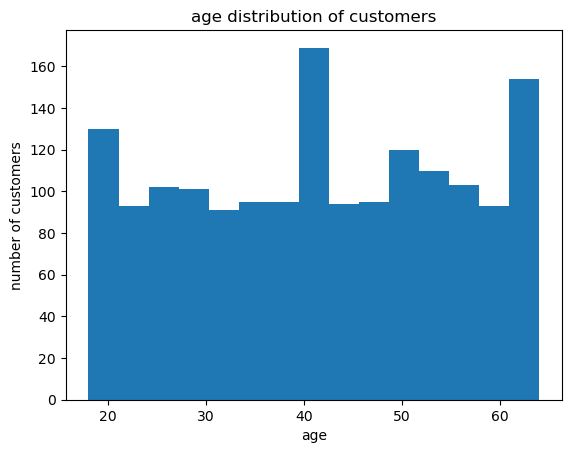

In [198]:
#Age distribution (Histogram)
#→ Who are our customers?

plt.figure()
plt.hist(df["age"].dropna(), bins=15)
plt.xlabel("age")
plt.ylabel("number of customers")
plt.title("age distribution of customers")
plt.show()

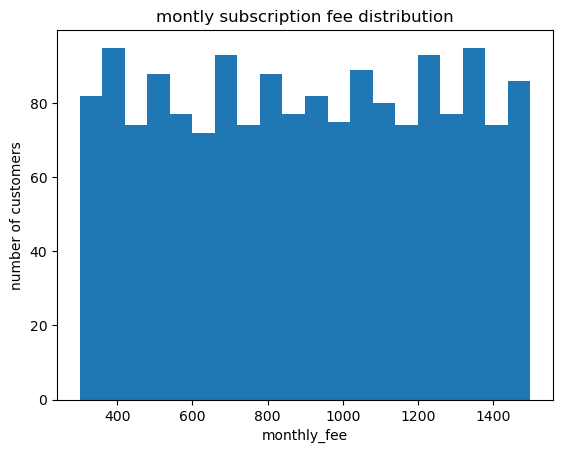

In [205]:
#2. Monthly fee distribution (Histogram)
#→ Pricing spread & skewness

plt.figure()
plt.hist(df["monthly_fee"], bins=20)
plt.xlabel("monthly_fee")
plt.ylabel("number of customers")
plt.title("montly subscription fee distribution")
plt.show()

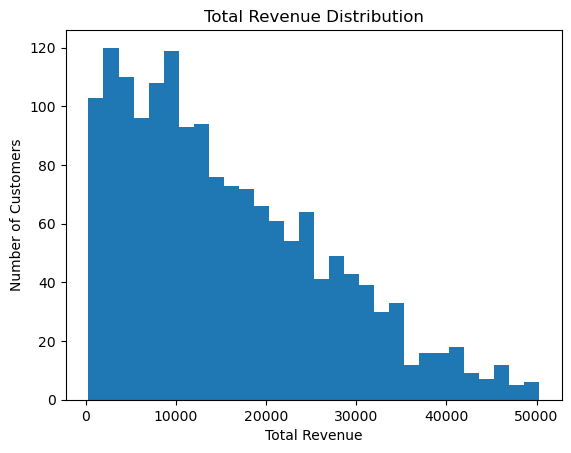

In [207]:
#3️ Total revenue distribution (Histogram)
#→ Revenue concentration

plt.figure()
plt.hist(df["total_revenue"], bins=30)
plt.xlabel("Total Revenue")
plt.ylabel("Number of Customers")
plt.title("Total Revenue Distribution")
plt.show()

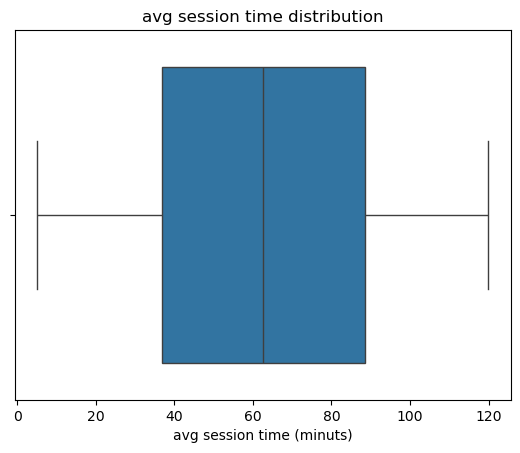

In [209]:
#4️ Avg session time distribution (Boxplot)
#→ Outliers & engagement spread

plt.figure()
sns.boxplot(x = df["avg_session_time"])
plt.xlabel("avg session time (minuts)")
plt.title("avg session time distribution")
plt.show()

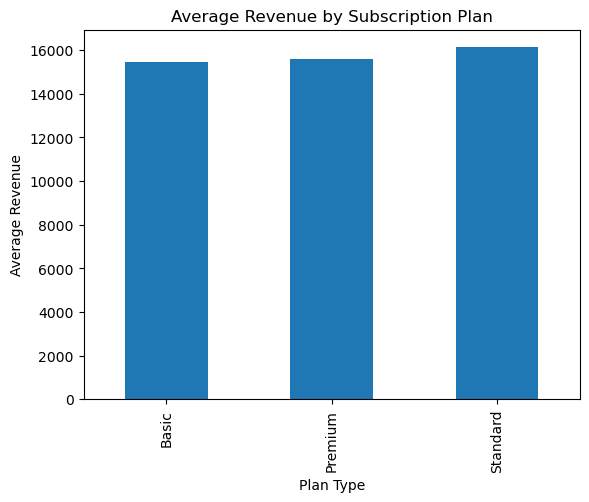

In [211]:
#B. Categorical Insights (4 visuals)
#These answer who and what drives outcomes.

#5️ Revenue by plan type (Bar chart)
#→ Which plan is most valuable?

plan_revenue = df.groupby("plan_type")["total_revenue"].mean().sort_values()
plan_revenue

plt.figure()
plan_revenue.plot(kind="bar")
plt.xlabel("Plan Type")
plt.ylabel("Average Revenue")
plt.title("Average Revenue by Subscription Plan")
plt.show()

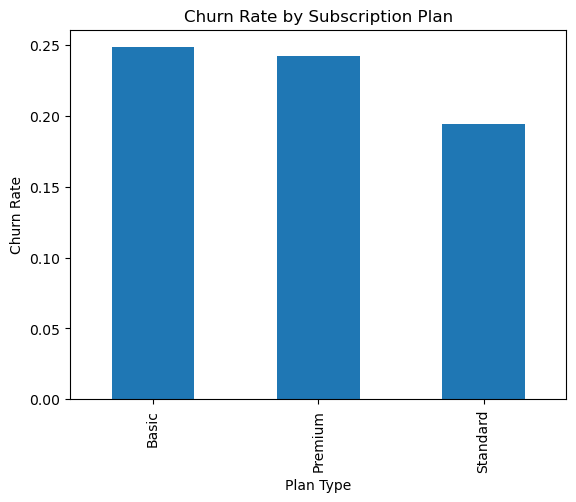

In [213]:
#6️ Churn rate by plan type (Bar chart)
#→ Which plans churn more?

churn_rate = (
    df.groupby("plan_type")["churned"]
    .apply(lambda x: (x == "Yes").mean()))

plt.figure()
churn_rate.plot(kind="bar")
plt.xlabel("Plan Type")
plt.ylabel("Churn Rate")
plt.title("Churn Rate by Subscription Plan")
plt.show()

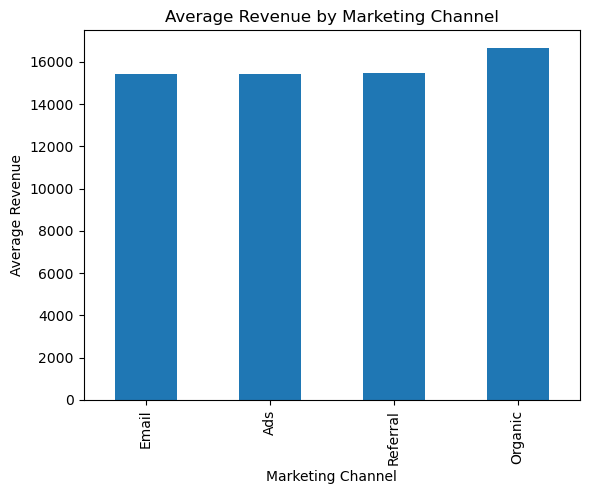

In [215]:
#7️ Revenue by marketing channel (Bar chart)
#→ Best acquisition source

channel_revenue = (
    df.groupby("marketing_channel")["total_revenue"]
    .mean()
    .sort_values()
)

plt.figure()
channel_revenue.plot(kind="bar")
plt.xlabel("Marketing Channel")
plt.ylabel("Average Revenue")
plt.title("Average Revenue by Marketing Channel")
plt.show()

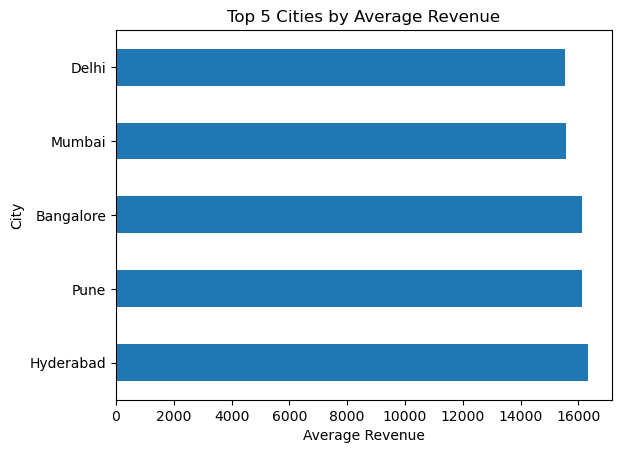

In [224]:
#8️ Revenue by city (Top 5) (Bar chart)
# Which cities contribute the most revenue?
city_revenue = (
    df.groupby("city")["total_revenue"]
    .mean()
    .sort_values(ascending=False)
    .head(5))

plt.figure()
city_revenue.plot(kind="barh")
plt.ylabel("City")
plt.xlabel("Average Revenue")
plt.title("Top 5 Cities by Average Revenue")
plt.show()


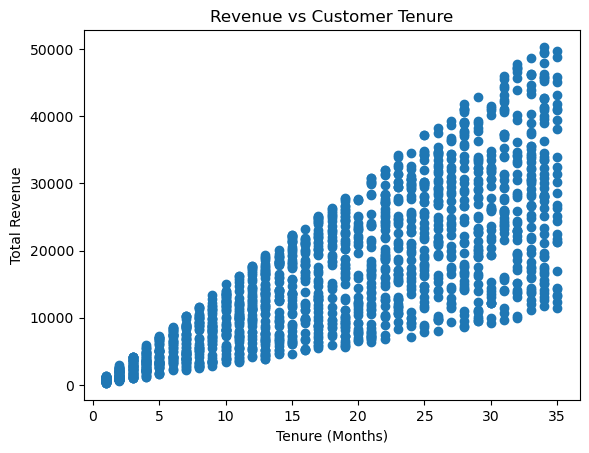

In [226]:
#C. Behavioral & Time-Based Trends (4 visuals)
#These show patterns and relationships.

#9️ Revenue vs tenure (Scatter + regression line)
#→ Does loyalty pay?

plt.figure()
plt.scatter(df["tenure_months"], df["total_revenue"])
plt.xlabel("Tenure (Months)")
plt.ylabel("Total Revenue")
plt.title("Revenue vs Customer Tenure")
plt.show()

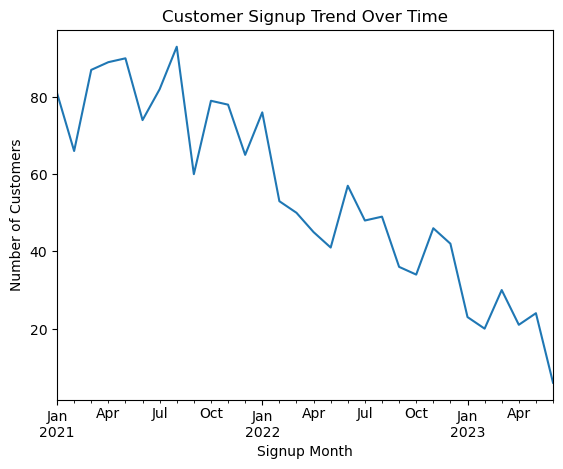

In [228]:
#10 Engagement score vs revenue (Scatter)
#→ Does engagement translate to money?

signup_trend = df.groupby(df["signup_date"].dt.to_period("M")).size()

plt.figure()
signup_trend.plot()
plt.xlabel("Signup Month")
plt.ylabel("Number of Customers")
plt.title("Customer Signup Trend Over Time")
plt.show()

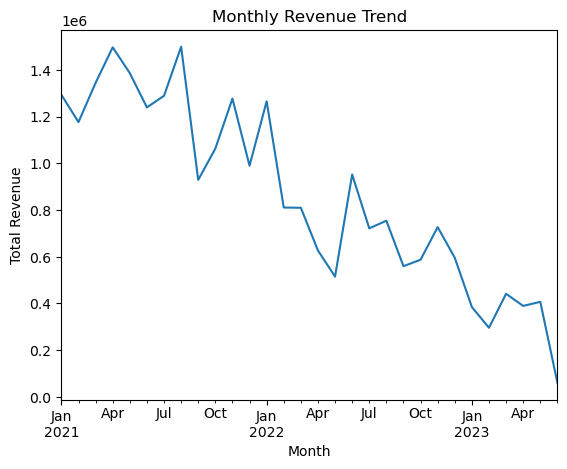

In [230]:
#11 Signup trend over time (Line chart)
#→ Growth pattern

monthly_revenue = (
    df.groupby(df["signup_date"].dt.to_period("M"))["total_revenue"]
    .sum())

plt.figure()
monthly_revenue.plot()
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.title("Monthly Revenue Trend")
plt.show()

In [ ]:
#1️2 Monthly revenue trend (Line chart)
#→ Seasonality & trend


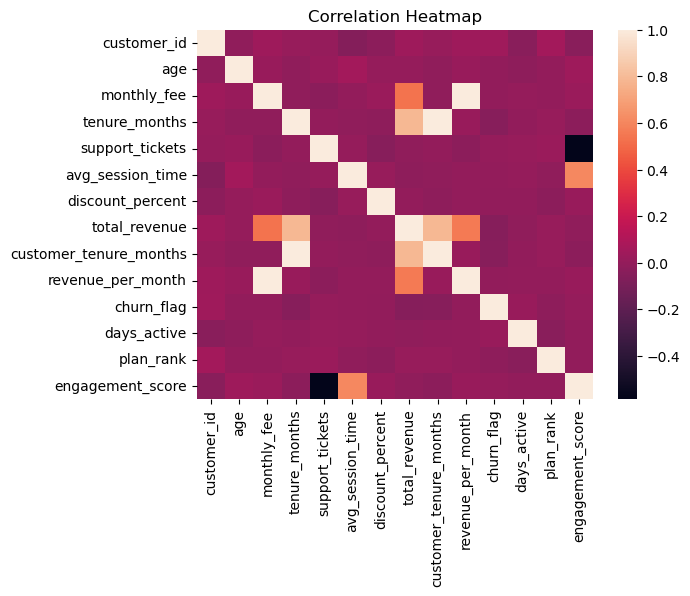

In [232]:
#Modeling Support Visuals (2 visuals)
#These directly support Linear Regression.

#13 Correlation heatmap
#→ Feature selection

# Correlation Heatmap
# Which variables have the strongest relationship with revenue?
# Are any features redundant or highly correlated?
# Select only numeric columns
numeric_df = df.select_dtypes(include=["int64", "float64"])

plt.figure()
sns.heatmap(numeric_df.corr(), annot=False)
plt.title("Correlation Heatmap")
plt.show()

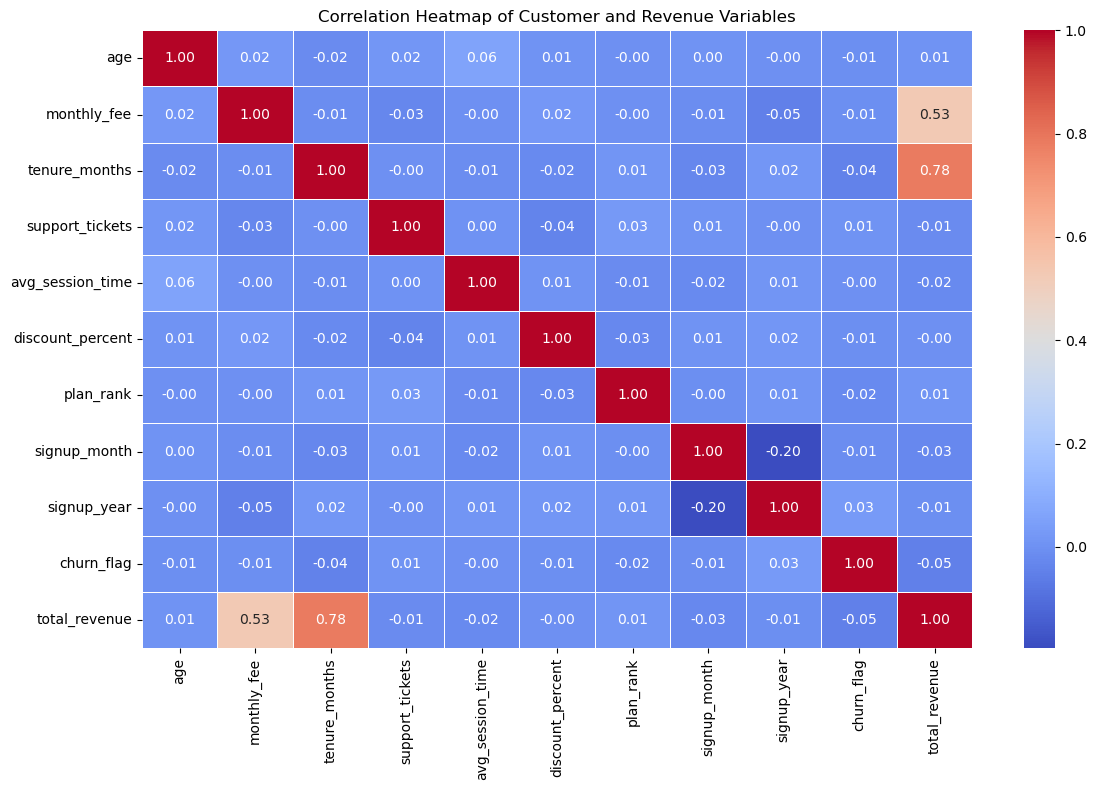

In [236]:
correlation_columns = [
    "age",
    "monthly_fee",
    "tenure_months",
    "support_tickets",
    "avg_session_time",
    "discount_percent",
    "plan_rank",
    "signup_month",
    "signup_year",
    "churn_flag",
    "total_revenue"
]

correlation_data = df[correlation_columns].copy()

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Customer and Revenue Variables")

plt.tight_layout()
plt.show()

C:\Users\visha\AppData\Local\Temp\ipykernel_30816\256398983.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["plan_rank"] = df["plan_type"].map(plan_map)
C:\Users\visha\AppData\Local\Temp\ipykernel_30816\256398983.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["engagement_score"] = df.apply(


Intercept: -15762.939685780126
            Feature  Coefficient
0     tenure_months   882.058870
1       monthly_fee    17.571979
2         plan_rank   113.585787
3  engagement_score    -3.672516
Mean Squared Error: 11424995.750603111
Root Mean Squared Error: 3380.088127638555
R-squared: 0.9149382986829313


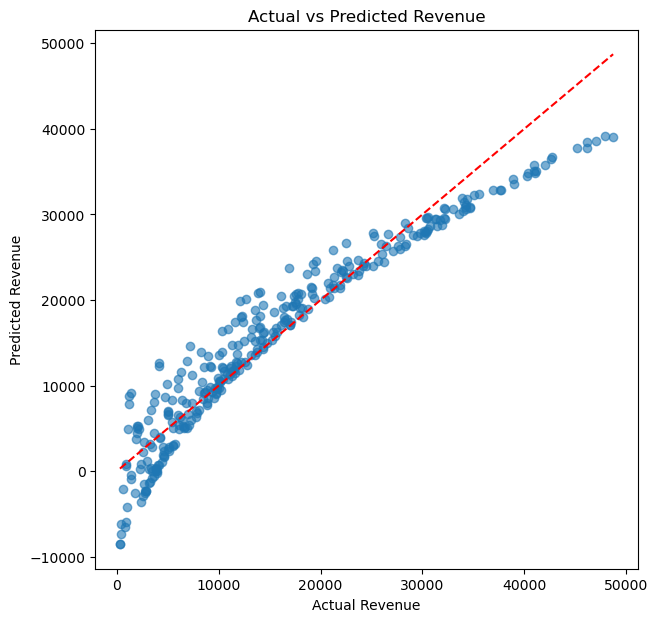

Predicted Revenue: 47394.214093770715


In [234]:
plan_map = {"Basic": 1, "Standard": 2, "Premium": 3}
df["plan_rank"] = df["plan_type"].map(plan_map)

df["engagement_score"] = df.apply(
    lambda x: x["avg_session_time"] / (x["support_tickets"] + 1), axis=1)
# print(df[["plan_rank", "engagement_score"]].head()) to verify columns exists in data set now

# X = df[["tenure_months", "monthly_fee", "plan_rank", "engagement_score"]]
# print(X.isna().sum()) - To check the count of NaN values in these columns (NaN values are not accepted for Regression)


# Combine features and target for cleaning
model_df = df[["tenure_months", "monthly_fee", "plan_rank", "engagement_score", "total_revenue"]]

# Drop rows with any missing value
model_df = model_df.dropna()

# Split X and y again
X = model_df[["tenure_months", "monthly_fee", "plan_rank", "engagement_score"]]
y = model_df["total_revenue"]

from sklearn.model_selection import train_test_split

# Split dataset: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

from sklearn.linear_model import LinearRegression

# Create the Linear Regression model object
lr_model = LinearRegression()

# Fit the model on training data
lr_model.fit(X_train, y_train)


# total_revenue ≈ intercept + coef1*tenure_months + coef2*monthly_fee + coef3*plan_rank + coef4*engagement_score

# Intercept
print("Intercept:", lr_model.intercept_)
  
# Coefficients
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": lr_model.coef_})
print(coef_df)


# Predict revenue for test data
y_pred = lr_model.predict(X_test)


from sklearn.metrics import mean_squared_error, r2_score

# Mean Squared Error (MSE) 
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

# Root Mean Squared Error (RMSE)
rmse = mse ** 0.5
print("Root Mean Squared Error:", rmse)

# R-squared
r2 = r2_score(y_test, y_pred)
print("R-squared:", r2)


import matplotlib.pyplot as plt

plt.figure(figsize=(7,7))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.xlabel("Actual Revenue")
plt.ylabel("Predicted Revenue")
plt.title("Actual vs Predicted Revenue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # Perfect prediction line
plt.show()

# Example new customer
new_customer = pd.DataFrame({
    "tenure_months": [12],
    "monthly_fee": [3000],
    "plan_rank": [1],  
    "engagement_score": [70]})

predicted_revenue = lr_model.predict(new_customer)
print("Predicted Revenue:", predicted_revenue[0])

In [244]:
import pandas as pd

data = {"hours": [1,2,3,4,5,6,7,8],"pass":[0,0,0,1,1,1,1,1]}
df= pd.DataFrame(data)

# Input and outputs for reg model (Logistic)
X = df[["hours"]]
y = df[["pass"]]

# SPLIT into Train and test
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train,X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42)

# model Logistic regression 
model = LogisticRegression()

# Fit model
model.fit(X_train,y_train)

# Predict
predictions = model.predict(X_test)

# Accuracy 
accuracy = accuracy_score(y_test, predictions)
print(accuracy)

hours = [[0.5]]

# PRedictions 
prediction = model.predict(hours)
probability = model.predict_proba(hours)

print(prediction)
print(probability)

C:\Users\visha\anaconda3\Lib\site-packages\sklearn\utils\validation.py:1339: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


1.0
[0]
[[0.93979764 0.06020236]]


C:\Users\visha\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
C:\Users\visha\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [246]:
import pandas as pd 
import numpy as np

np.random.seed(42)

n = 600
area = np.random.randint(500,4000,n)
bedrooms = np.random.randint(1,6,n)
age = np.random.randint(0,30,n)
location = np.random.choice(["Rural","Urban","suburban"],n)

price = (area * 1800 + bedrooms * 250000 - age * 40000 + np.random.randint(-400000,400000,n))

df = pd.DataFrame({"area_sft":area,"NBR":bedrooms,"age_":age, "location":location,"cost":price})

# Label encoder()
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["location"] = le.fit_transform(df["location"])
df

# Decision tree model
# Step 1
# Input variable and output variable

X = df.drop("cost",axis = 1)
y = df["cost"]
# Split into Train and test model
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_squared_error, r2_score

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42)

model = RandomForestRegressor(n_estimators = 200, max_depth = 10, random_state = 42)

# Train the model (Fitting)

model.fit(X_train,y_train)

# Y-rediction
y_pred = model.predict(X_test)

# Accuracy

# Mean Squared Error (MSE) 
mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)

# Root Mean Squared Error (RMSE)
rmse = mse ** 0.5
print("Root Mean Squared Error:", rmse)

# R-squared
r2 = r2_score(y_test, y_pred)
print("R-squared:", r2)

# Prediction
sample_house = np.array([[3500,6,3,2]])
prediction = model.predict(sample_house)

print(prediction)

Mean Squared Error: 99115207703.20944
Root Mean Squared Error: 314825.67827801063
R-squared: 0.9711275071467276
[7447768.1895]


C:\Users\visha\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


In [248]:
!pip install xgboost
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor
# For random forest replace the above line with the below line
# from sklearn.ensembler import RandomForestRegressor

np.random.seed(42)
n = 700

area = np.random.randint(500,4000,n)
bedrooms = np.random.randint(1,6,n)
age = np.random.randint(0,30,n)
location = np.random.choice(["Rural","Urban","suburban"],n)

price = (area * 2000 + bedrooms * 300000 - age * 50000 + np.random.randint(-100000, 100000, n))

df = pd.DataFrame({"area_":area ,"bedrooms_" : bedrooms , "age_": age, "location_":location,"price_":price})

le = LabelEncoder()
df["location_"] = le.fit_transform(df["location_"])


# Decide what is X and Y variables

X = df.drop("price_", axis = 1)
y = df["price_"]

# SPlit the data into 80 - 20 rule
X_train, X_test, y_train, y_test = train_test_split(X, y , test_size = 0.2, random_state = 42)

# Model training
model = XGBRegressor(n_estimator = 200, learning_rate = 0.1, max_depth = 5, random_state = 42)
# For random forest
# change the above line with the below line

# model = RandomForestRegressor()
# Inputs (N_estimator, max_depth, random_state = 42)

# Fit the model
model.fit(X_train,y_train)

# Predict Y 
y_pred  = model.predict(X_test)

# Evaluations Accuracy

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(mse)
print(rmse)
print(r2)

sample_house = np.array([[2000,3,7,1]])
prediction = model.predict(sample_house)

print(prediction)

ERROR: Could not find a version that satisfies the requirement xgboost (from versions: none)
ERROR: No matching distribution found for xgboost


ModuleNotFoundError: No module named 'xgboost'

In [ ]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# -------------------------
# STEP 1: CREATE SYNTHETIC DATASET (500+ records)
# -------------------------
np.random.seed(42)

n = 600

area = np.random.randint(500, 4000, n)
bedrooms = np.random.randint(1, 6, n)
bathrooms = np.random.randint(1, 5, n)
age = np.random.randint(0, 30, n)

location = np.random.choice(["Rural", "Suburban", "Urban"], n)

# Price formula with noise
price = (
    area * 1800 +
    bedrooms * 250000 +
    bathrooms * 150000 -
    age * 40000 +
    np.random.randint(-400000, 400000, n)
)

df = pd.DataFrame({
    "Area_sqft": area,
    "Bedrooms": bedrooms,
    "Bathrooms": bathrooms,
    "Location": location,
    "Age": age,
    "Price": price
})

print(df.head())

# -------------------------
# STEP 2: ENCODE CATEGORICAL DATA
# -------------------------
le = LabelEncoder()
df["Location"] = le.fit_transform(df["Location"])

# -------------------------
# STEP 3: SPLIT FEATURES AND TARGET
# -------------------------
X = df.drop("Price", axis=1)
y = df["Price"]

# -------------------------
# STEP 4: TRAIN-TEST SPLIT
# -------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# -------------------------
# STEP 5: FEATURE SCALING (VERY IMPORTANT FOR KNN)
# -------------------------
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# -------------------------
# STEP 6: TRAIN KNN MODEL
# -------------------------
# It will search for nearest 5 neighbours and takes the avg 
model = KNeighborsRegressor(n_neighbors=5)  

model.fit(X_train, y_train)

# -------------------------
# STEP 7: PREDICTION
# -------------------------
y_pred = model.predict(X_test)

# -------------------------
# STEP 8: EVALUATION
# -------------------------
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nMODEL PERFORMANCE (KNN)")
print("-----------------------")
print("MSE :", mse)
print("RMSE:", rmse)
print("R2  :", r2)

# -------------------------
# STEP 9: PREDICT NEW HOUSE
# -------------------------
new_house = np.array([[2000, 3, 2, 2, 10]])  # Urban encoded = 2

new_house_scaled = scaler.transform(new_house)

prediction = model.predict(new_house_scaled)

print("\nPREDICTION")
print("-----------------------")
print("Predicted Price:", prediction[0])



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# -----------------------------
# STEP 1: CREATE HOUSE DATASET
# -----------------------------
np.random.seed(42)

n = 600

area = np.random.randint(500, 4000, n)
bedrooms = np.random.randint(1, 6, n)
bathrooms = np.random.randint(1, 5, n)
age = np.random.randint(0, 30, n)

df = pd.DataFrame({
    "Area_sqft": area,
    "Bedrooms": bedrooms,
    "Bathrooms": bathrooms,
    "Age": age
})

print(df.head())

# -----------------------------
# STEP 2: FEATURE SCALING (VERY IMPORTANT)
# -----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# -----------------------------
# STEP 3: APPLY K-MEANS
# -----------------------------
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

df["Cluster"] = clusters

print("\nCluster Counts:")
print(df["Cluster"].value_counts())

# -----------------------------
# STEP 4: VISUALIZATION (2D PLOT)
# -----------------------------
plt.figure(figsize=(8,6))

plt.scatter(df["Area_sqft"], df["Bedrooms"], c=df["Cluster"], cmap="viridis")

plt.xlabel("Area (sqft)")
plt.ylabel("Bedrooms")
plt.title("House Clusters using K-Means")
plt.colorbar(label="Cluster")
plt.show()

# -----------------------------
# STEP 5: NEW HOUSE PREDICTION (CLUSTER)
# -----------------------------
new_house = np.array([[2000, 3, 2, 10]])  # area, bedrooms, bathrooms, age

new_house_scaled = scaler.transform(new_house)

cluster = kmeans.predict(new_house_scaled)

print("\nNew House belongs to Cluster:", cluster[0])

